# Clasificación landuse con DenseNet121

DenseNet conecta cada capa con todas las anteriores dentro de un bloque denso:
la entrada de la capa `l` es la concatenación de las salidas de las capas
`0..l-1`. Eso reutiliza características, reduce parámetros y mejora el flujo del
gradiente.

Se parte de `DenseNet121` preentrenada en ImageNet y se adapta la cabeza a las
tres clases del reto en dos fases:

1. **Fase 1** — base congelada, se entrena solo la cabeza clasificadora.
2. **Fase 2** — se descongelan las últimas capas del bloque `conv5` y se hace
   fine-tuning con un learning rate bajo.

Las imágenes se redimensionan a 128×128 y se preprocesan con
`keras.applications.densenet.preprocess_input`. El modelo se carga desde
`resultados/densenet/` por defecto; cambia `FORCE_RETRAIN = True` para
reentrenarlo.

## Configuración

In [1]:
import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from keras import layers
from keras.applications import DenseNet121
from keras.applications.densenet import preprocess_input
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam

import common_landuse as cl

FORCE_RETRAIN = False
sns.set_theme(style="whitegrid", context="notebook")
keras.utils.set_random_seed(cl.SEED)
np.random.seed(cl.SEED)

I0000 00:00:1794800592.969503   92181 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794800593.065450   92181 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794800595.904564   92181 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Carga del dataset y split común

In [2]:
data = cl.load_split_data()
X_train = data["X_train"].astype("float32")
X_val = data["X_val"].astype("float32")
X_test = data["X_test"].astype("float32")
y_train_labels = data["y_train"]
y_val_labels = data["y_val"]
y_test_labels = data["y_test"]
test_paths = data["test_paths"]

y_train = cl.one_hot(y_train_labels)
y_val = cl.one_hot(y_val_labels)

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Test distribution:", {name: int(np.sum(y_test_labels == name)) for name in cl.CLASSES})

Train: (956, 128, 128, 3) | Validation: (169, 128, 128, 3) | Test: (375, 128, 128, 3)
Test distribution: {'denseresidential': 125, 'harbor': 125, 'river': 125}


## Modelo, entrenamiento y evaluación

In [3]:
def build_densenet():
    inputs = layers.Input(shape=(128, 128, 3))
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.10)(x)
    x = layers.RandomTranslation(0.08, 0.08)(x)
    x = layers.Lambda(preprocess_input, name="densenet_preprocessing")(x)

    base = DenseNet121(include_top=False, weights="imagenet", input_shape=(128, 128, 3))
    base.trainable = False

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    outputs = layers.Dense(len(cl.CLASSES), activation="softmax")(x)
    model = keras.Model(inputs, outputs, name="densenet121_landuse")
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-3),
        metrics=["accuracy"],
    )
    return model


def fit_densenet(model):
    base = model.get_layer("densenet121")
    phase1_callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    ]
    history_phase1, seconds_phase1 = cl.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=12,
        batch_size=32,
        callbacks=phase1_callbacks,
    )

    for layer in base.layers[-40:]:
        if not isinstance(layer, layers.BatchNormalization):
            layer.trainable = True
    model.compile(
        loss="categorical_crossentropy",
        optimizer=Adam(learning_rate=1e-5),
        metrics=["accuracy"],
    )

    phase2_callbacks = [
        EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ]
    history_phase2, seconds_phase2 = cl.train_keras_model(
        model,
        X_train,
        y_train,
        X_val,
        y_val,
        epochs=12,
        batch_size=32,
        callbacks=phase2_callbacks,
    )

    history = pd.concat(
        [pd.DataFrame(history_phase1.history), pd.DataFrame(history_phase2.history)],
        ignore_index=True,
    )
    history.index = np.arange(1, len(history) + 1)
    return model, history, seconds_phase1 + seconds_phase2


def evaluate_densenet(model, history, training_seconds):
    predicted_idx, probabilities, inference_ms = cl.predict_keras(model, X_test)
    predicted = np.array(cl.CLASSES)[predicted_idx]
    metrics = cl.compute_metrics(
        name="DenseNet121",
        family="DL (non-sequential)",
        y_true=y_test_labels,
        y_pred=predicted,
        y_prob=probabilities,
        params=model.count_params(),
        trainable_params=sum(np.prod(weight.shape) for weight in model.trainable_weights),
        training_seconds=training_seconds,
        inference_ms=inference_ms,
        epochs=len(history),
        hyperparameters={
            "base": "DenseNet121 ImageNet",
            "input": 128,
            "phase1_lr": 1e-3,
            "phase2_lr": 1e-5,
            "batch_size": 32,
            "epochs_phase1": 12,
            "epochs_phase2": 12,
            "dropout": 0.35,
            "fine_tuning_layers": 40,
        },
        notes="DenseNet121 pretrained on ImageNet with fine-tuning of the conv5 block.",
    )
    cl.save_results(
        "densenet",
        metrics,
        y_test_labels,
        predicted,
        probabilities,
        test_paths=test_paths,
        history=history,
        model=model,
    )
    return metrics

In [4]:
model, history, metrics, retrained = cl.load_or_train(
    "densenet",
    build_model=build_densenet,
    fit_model=fit_densenet,
    evaluate_model=evaluate_densenet,
    force=FORCE_RETRAIN,
)
print("Test accuracy:", round(metrics["accuracy"], 4))

E0000 00:00:1794800606.155618   92181 cuda_executor.cc:1690] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:68

W0000 00:00:1794800606.156502   92247 cuda_executor.cc:1710] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:77
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:107
external/xla/xla/stream_executor/cuda/cudnn_api_wrappers.cc:112

W0000 00:00:1794800606.175263   92181 dlopen_checker.cc:38] Could not load dynamic library 'libcudart.so.12'; dlerror: libcudart.so.12: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: /home/andres/Des

[cache] Using trained model from /home/andres/Desktop/vision-por-computador/guia-4/reto-2/resultados/densenet
Test accuracy: 0.9893


## Grad-CAM: ¿dónde mira la red?

W0000 00:00:1794800623.031897   92181 cpu_allocator_impl.cc:174] Allocation of 28311552 exceeds 10% of free system memory.
W0000 00:00:1794800623.046493   92181 cpu_allocator_impl.cc:174] Allocation of 28311552 exceeds 10% of free system memory.
W0000 00:00:1794800623.061513   92181 cpu_allocator_impl.cc:174] Allocation of 28311552 exceeds 10% of free system memory.
W0000 00:00:1794800623.077640   92181 cpu_allocator_impl.cc:174] Allocation of 28311552 exceeds 10% of free system memory.
W0000 00:00:1794800623.093684   92181 cpu_allocator_impl.cc:174] Allocation of 28311552 exceeds 10% of free system memory.


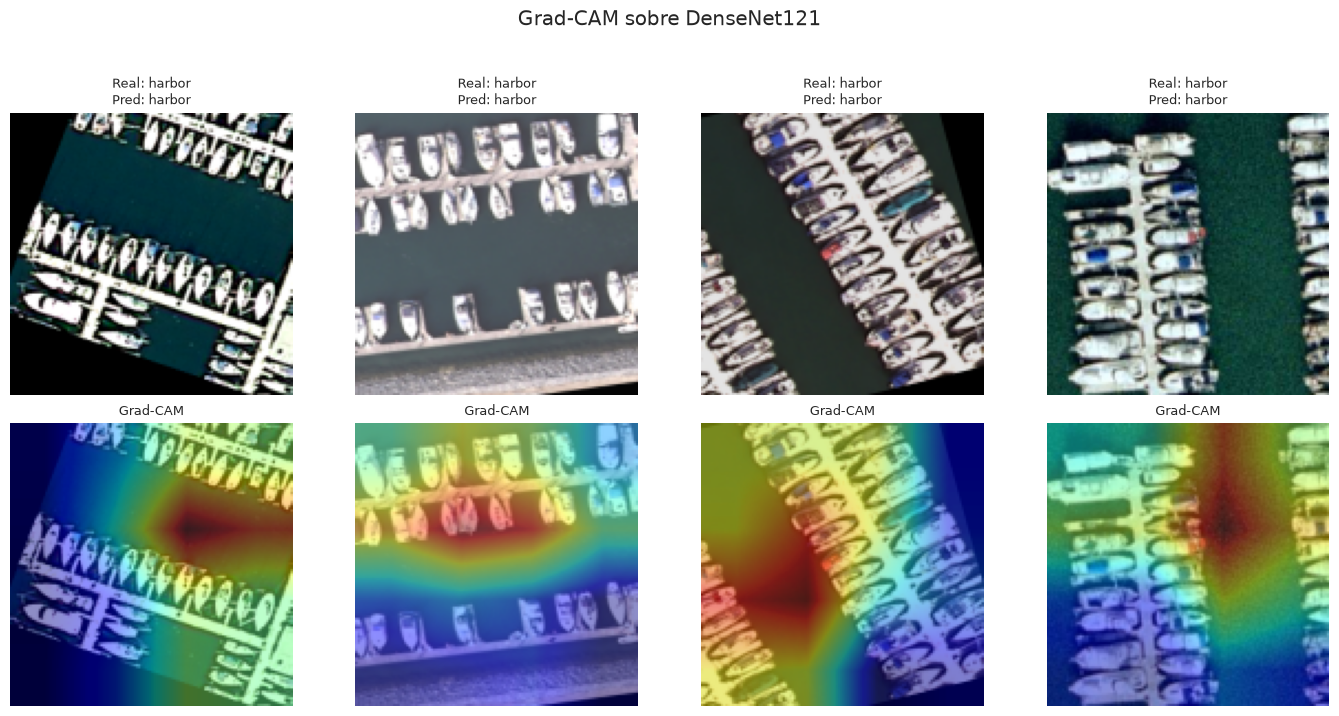

In [5]:
base = model.get_layer("densenet121")
conv_layer = base.get_layer("conv5_block16_concat")
grad_model = keras.Model(base.input, [conv_layer.output, base.output])

gap = next(layer for layer in model.layers if isinstance(layer, layers.GlobalAveragePooling2D))
dropout = next(layer for layer in model.layers if isinstance(layer, layers.Dropout))
classifier = next(layer for layer in model.layers if isinstance(layer, layers.Dense))


def grad_cam(image, class_index):
    with tf.GradientTape() as tape:
        conv_output, features = grad_model(
            preprocess_input(image[None].astype("float32")), training=False
        )
        predictions = classifier(dropout(gap(features), training=False))
        loss = predictions[:, class_index]
    gradients = tape.gradient(loss, conv_output)
    weights = tf.reduce_mean(gradients, axis=(0, 1, 2))
    heatmap = tf.reduce_mean(conv_output[0] * weights, axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


rng = np.random.default_rng(cl.SEED)
indices = rng.choice(len(X_test), size=4, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for column, index in enumerate(indices):
    image = X_test[index]
    predicted_index = int(np.argmax(model.predict(image[None], verbose=0)[0]))
    heatmap = grad_cam(image, predicted_index)
    heatmap = tf.image.resize(heatmap[..., None], (128, 128)).numpy()[..., 0]

    axes[0, column].imshow(image.astype("uint8"))
    axes[0, column].set_title(
        f"Real: {y_test_labels[index]}\nPred: {cl.CLASSES[predicted_index]}", fontsize=9
    )
    axes[0, column].axis("off")

    axes[1, column].imshow(image.astype("uint8"))
    axes[1, column].imshow(heatmap, cmap="jet", alpha=0.45)
    axes[1, column].set_title("Grad-CAM", fontsize=9)
    axes[1, column].axis("off")

fig.suptitle("Grad-CAM sobre DenseNet121", y=1.02)
fig.tight_layout()
fig.savefig(cl.result_dir("densenet") / "gradcam.png", dpi=150, bbox_inches="tight")
plt.show()

## Observaciones

* El preentrenamiento en ImageNet aporta filtros genéricos de bordes, texturas y
  formas; el fine-tuning los especializa en las tres clases con muy pocas épocas.
* DenseNet reutiliza características de todas las capas anteriores, lo que da una
  precisión muy alta y convergencia rápida.
* Grad-CAM permite interpretar la decisión: en `river` y `harbor` la red mira el
  agua y la línea de costa; en `denseresidential`, los patrones repetitivos de
  edificios y calles.
* Los resultados completos quedan en `resultados/densenet/` y la figura de
  interpretabilidad en `resultados/densenet/gradcam.png`.